# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Ляшко Леся'
LIST_NUMBER  = 11

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 11, файл lr6_варіант_11.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

встановлюю: shap ...
усі пакети на місці



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: pip3.13 install --upgrade pip


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
TYPE_OF_TASK='класифікація' # прогнозуємо бінарну подію відтоку
METRIC='AUC' # не залежить від порога й коректна при дисбалансі класів
CV_SCHEME='стратифікована 5-кратна крос-валідація, 4 повтори' # 20 оцінок з різними розбиттями
print(TYPE_OF_TASK,METRIC,CV_SCHEME)

класифікація AUC стратифікована 5-кратна крос-валідація, 4 повтори


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.247

типи стовпців: {'object': 14, 'float64': 6, 'int64': 6}


In [6]:
display(pd.DataFrame([{'стовпець':c,'тип':str(raw[c].dtype),'унікальних':raw[c].nunique(),'пропусків_%':round(raw[c].isna().mean()*100,1),'приклад':str(raw[c].dropna().iloc[0]) if raw[c].notna().any() else ''} for c in raw]).sort_values('пропусків_%',ascending=False))

,стовпець,тип,унікальних,пропусків_%,приклад
23,дата_розірвання,object,241,75.3,2025-01-23
22,код_причини_закриття,object,5,75.3,ІНШ-09
17,середній_час_відповіді_хв,float64,260,34.0,8.8
14,трафік_ГБ,object,961,5.0,131.2
12,щомісячний_платіж,object,1137,4.0,268.95
16,аварій_на_ділянці_за_квартал,float64,6,3.0,0.0
0,id_клієнта,object,1200,0.0,K110000
24,кількість_дзвінків_утримання,int64,6,0.0,0
21,дата_підключення,object,593,0.0,2024-05-14
20,індекс_лояльності_CRM,float64,1197,0.0,5.961


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [74]:
for c in ['щомісячний_платіж','трафік_ГБ','аварій_на_ділянці_за_квартал','середній_час_відповіді_хв']:
 print(c,raw[c].dropna().astype(str).head(12).tolist())

print('Excel-дати:',raw.loc[raw['трафік_ГБ'].astype(str).str.contains('1900|/',regex=True),'трафік_ГБ'].head(12).tolist())
print('Пропуск часу відповіді за кількістю звернень:');display(pd.crosstab(raw['кількість_звернень_у_підтримку'].eq(0),raw['середній_час_відповіді_хв'].isna(),normalize='index'))

щомісячний_платіж ['268.95', '413.66', '294.82', '370.48', '264.65', '291.17', '309.71', '286.31', '208.29', '294.83', '335.32', '227.41']
трафік_ГБ ['131.2', '189.1', '97.5', '178.6', '112.4', '165.8', '120.2', '202.5', '208.4', '127.4', '197.6', '105.6']
аварій_на_ділянці_за_квартал ['0.0', '0.0', '0.0', '0.0', '0.0', '1.0', '0.0', '1.0', '2.0', '1.0', '1.0', '1.0']
середній_час_відповіді_хв ['8.8', '13.6', '12.0', '5.7', '6.4', '6.4', '2.4', '6.7', '12.5', '23.6', '7.4', '6.3']
Excel-дати: ['1900-01-10 00:00:00', '1900-01-18 00:00:00', '1900-01-02 00:00:00']
Пропуск часу відповіді за кількістю звернень:


середній_час_відповіді_хв,False,True
кількість_звернень_у_підтримку,,
False,1.0,0.0
True,0.0,1.0


In [8]:
PROBLEM_TEXT_IN_NUMBER='щомісячний_платіж'
PROBLEM_EXCEL_DATE='трафік_ГБ'
PROBLEM_MNAR='середній_час_відповіді_хв'
MNAR_MEANING='Коли клієнт не звертався до підтримки, часу відповіді не існує, тому пропуск є змістовним.'
assert all(c in raw.columns for c in [PROBLEM_TEXT_IN_NUMBER,PROBLEM_EXCEL_DATE,PROBLEM_MNAR]);print(MNAR_MEANING)

Коли клієнт не звертався до підтримки, часу відповіді не існує, тому пропуск є змістовним.


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
def to_number(s):
    """Перетворення чисел і тексту; пошкоджені Excel дати -> NaN."""
    def one(v):
        if pd.isna(v) or isinstance(v,(datetime.datetime,datetime.date,pd.Timestamp)):
            return np.nan
        if isinstance(v,(int,float,np.number)):
            return float(v)
        t=str(v).strip()
        if re.search(r'(?i)(?:19|20)\d\d[-/]\d{1,2}[-/]\d{1,2}|\d{1,2}[-/]\d{1,2}[-/](?:19|20)\d\d',t):
            return np.nan
        m=re.search(r'[-+]?(?:\d+(?:[.,]\d+)?|[.,]\d+)',t.replace(' ',''))
        return float(m.group().replace(',','.')) if m else np.nan
    return s.map(one)

_t=pd.Series([1,'350.5 грн','2,75',datetime.datetime(1900,1,11),None,'немає'])
_r=to_number(_t)
assert _r[0]==1 and abs(_r[1]-350.5)<1e-9 and abs(_r[2]-2.75)<1e-9
assert np.isnan(_r[3]) and np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS=['id_клієнта']
def build_X(d,drop):
    X=pd.DataFrame(index=d.index);log=[]
    for c in d.columns:
        if c in drop or c==TARGET:continue
        s=d[c]
        if c=='дата_підключення':
            dt=pd.to_datetime(s,errors='coerce');X[c]=(dt-pd.Timestamp('2020-01-01')).dt.days.astype(float);kind='число (днів від 2020-01-01)'
        elif pd.api.types.is_numeric_dtype(s):
            X[c]=s.astype(float);kind='число'
        else:
            converted=to_number(s)
            ratio=converted.notna().sum()/max(1,s.notna().sum())
            if ratio>0.80:
                X[c]=converted.astype(float);kind='число з тексту'
            else:
                X[c]=s.astype('string').str.strip().str.lower().replace({'':np.nan}).astype('object').fillna(np.nan);kind='категорія'
        log.append({'стовпець':c,'рішення':kind})
    return X,pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 0


,стовпець,рішення
0,вік,число
1,стать,категорія
2,місто,категорія
3,філія,число з тексту
4,тариф,категорія
5,тип_підключення,категорія
6,спосіб_оплати,категорія
7,автоплатіж,категорія
8,кількість_послуг,число
9,місяців_обслуговування,число


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X,clf):
    num=X.select_dtypes(include='number').columns.tolist()
    cat=[c for c in X if c not in num]
    prep=ColumnTransformer([
      ('num',Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),('scale',StandardScaler())]),num),
      ('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cat)
    ],sparse_threshold=0)
    return Pipeline([('prep',prep),('clf',clf)])

def logreg():return LogisticRegression(max_iter=3000,random_state=SEED)
cv=RepeatedStratifiedKFold(n_splits=5,n_repeats=4,random_state=SEED)
_p=make_pipe(X_all,logreg())
_s=cross_val_score(_p,X_all,y,cv=RepeatedStratifiedKFold(n_splits=5,n_repeats=1,random_state=SEED),scoring='roc_auc')
print('конвеєр працює, AUC:',_s.mean())

конвеєр працює, AUC: 1.0


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 1.000 ± 0.000
час      : 0.3 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [75]:
FIRST_REACTION='Надзвичайно висока AUC, найімовірніше, спричинена витоком інформації про майбутнє розірвання договору, або ж задача проста.'
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

Надзвичайно висока AUC, найімовірніше, спричинена витоком інформації про майбутнє розірвання договору, або ж задача проста.


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [76]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows=[]
    for c in d.columns:
        if c==TARGET:continue
        mask=d[c].notna()
        if mask.sum()<min_group or (~mask).sum()<min_group:continue
        score=roc_auc_score(y,mask.astype(int))
        rows.append({'ознака':c,'заповнено':int(mask.sum()),'частка_відтоку_де_заповнено':float(y[mask].mean()),'частка_відтоку_де_пропуск':float(y[~mask].mean()),'показник':max(score,1-score)})
    return pd.DataFrame(rows).sort_values('показник',ascending=False)
scan=leak_scan(raw,y);display(scan.head(24))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
4,код_причини_закриття,296,1.000000,0.000000,1.000000
5,дата_розірвання,296,1.000000,0.000000,1.000000
3,середній_час_відповіді_хв,792,0.276515,0.188725,0.553008
2,аварій_на_ділянці_за_квартал,1164,0.249141,0.166667,0.506458
0,щомісячний_платіж,1152,0.247396,0.229167,0.501884
1,трафік_ГБ,1140,0.246491,0.250000,0.500448


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK=['код_причини_закриття','дата_розірвання'] # виникають лише після закриття договору
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['код_причини_закриття', 'дата_розірвання']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.926 ± 0.014


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [77]:
print(list(X2.columns))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'трафік_МБ', 'номер_договору_серія', 'індекс_лояльності_CRM', 'дата_підключення', 'кількість_дзвінків_утримання']


In [78]:
HUMAN_LEAK=['кількість_дзвінків_утримання'] # дзвінки відділу утримання відбуваються після оцінки ризику
HUMAN_LEAK_WHY='Поле заповнене і нулями, і ненульовими значеннями для обох класів, тому детектор пропусків не бачить витоку; кількість дзвінків відома тільки після рішення про утримання.'

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.846 ± 0.024


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

In [20]:
display(raw.groupby('філія')['відтік'].agg(['mean','size']).sort_values('mean',ascending=False))
q=pd.to_datetime(raw['дата_підключення']).dt.to_period('Q')
display(raw.groupby(q)['відтік'].agg(['mean','size']))

,mean,size
філія,,
Ф-01 Центр,0.422111,199
Ф-02 Захід,0.397849,186
Ф-03 Схід,0.214286,182
Ф-06 Приміська,0.172414,203
Ф-04 Південь,0.163462,208
Ф-05 Північ,0.135135,222


,mean,size
дата_підключення,,
2023Q1,0.194030,134
2023Q2,0.196203,158
2023Q3,0.250000,160
2023Q4,0.324324,148
2024Q1,0.241830,153
2024Q2,0.182927,164
2024Q3,0.319444,144
2024Q4,0.273381,139


### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [21]:
SUSPECT='філія'
source=raw['філія'].isin(['Ф-01 Центр','Ф-02 Захід']).astype(int)


X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.700
ті самі ознаки передбачають ВІДТІК  : AUC 0.815 ± 0.027


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [22]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,1.000
2. мінус цільовий витік,22,0.926
3. мінус оцінки людини,21,0.846
4. мінус артефакт збору,20,0.815


чесне число: 0.815 ± 0.027


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [79]:
DECISION_ARTEFACT='викинути'
DECISION_WHY='модель має працювати не лише у філіях, на яких навчалася, а й в інших. Якщо вона покладається на особливості збору даних конкретної філії, якість може погіршитися при перенесенні.'
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

викинути — модель має працювати не лише у філіях, на яких навчалася, а й в інших. Якщо вона покладається на особливості збору даних конкретної філії, якість може погіршитися при перенесенні.


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [24]:
from sklearn.tree import DecisionTreeClassifier
MODELS={'логістична регресія':logreg(),'одне дерево':DecisionTreeClassifier(max_depth=5,min_samples_leaf=15,random_state=SEED),'випадковий ліс':RandomForestClassifier(n_estimators=70,min_samples_leaf=3,random_state=SEED,n_jobs=-1),'гістограмний бустинг':HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=15,random_state=SEED)}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.815,0.027,0.3
одне дерево,0.750,0.035,0.2
випадковий ліс,0.824,0.029,1.6
гістограмний бустинг,0.827,0.032,5.9


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [30]:
def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    delta=np.asarray(b)-np.asarray(a)
    return float(delta.mean()),float(1.96*delta.std(ddof=1)/np.sqrt(len(delta)))

base=cross_val_score(make_pipe(X4,logreg()),X4,y,cv=cv,scoring='roc_auc')
MODEL_GAINS={}

base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other=cross_val_score(make_pipe(X4,MODELS[name]),X4,y,cv=cv,scoring='roc_auc')
    m,h=paired(base,other);MODEL_GAINS[name]=(m,h)
    print(name,'приріст AUC %.4f ± %.4f'%(m,h))

випадковий ліс приріст AUC 0.0092 ± 0.0089
гістограмний бустинг приріст AUC 0.0129 ± 0.0115


In [25]:
CHOSEN_MODEL='логістична регресія'
CHOSEN_WHY='Проста, швидка, інтерпретована базова модель; складніші методи оцінено за AUC, розкидом і часом, а прирости перевірено парно.'
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: логістична регресія — Проста, швидка, інтерпретована базова модель; складніші методи оцінено за AUC, розкидом і часом, а прирости перевірено парно.


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [27]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F=X.copy()
    # Невдоволення: звернення і аварії разом підсилюють ризик.
    F['звернення_на_аварію']=F['кількість_звернень_у_підтримку']/(1+F['аварій_на_ділянці_за_квартал'])
    # Вартість одного Мбіт відображає цінність тарифу для абонента.
    F['ціна_за_Мбіт']=F['щомісячний_платіж']/(1+F['швидкість_тарифу_Мбіт'])
    # Вартість на одиницю трафіку — проксі вигідності користування.
    F['ціна_за_ГБ']=F['щомісячний_платіж']/(1+F['трафік_ГБ'])
    # Відношення трафіку до швидкості показує інтенсивність використання.
    F['навантаження_тарифу']=F['трафік_ГБ']/(1+F['швидкість_тарифу_Мбіт'])
    return F
X5=add_features(X4)
assert X5.shape[1]>=X4.shape[1]+3
print('ознак:',X4.shape[1],'->',X5.shape[1])

ознак: 20 -> 24


In [28]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.811 ± 0.026
приріст проти базового набору: -0.0037 ± 0.0012   значуще


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [31]:
FEATURES_VS_MODEL='Нові ознаки: ΔAUC %.4f ± %.4f; випадковий ліс: ΔAUC %.4f ± %.4f. Час порівняння моделей наведено в таблиці розділу 7.'%(m,h,*MODEL_GAINS['випадковий ліс'])
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

Нові ознаки: ΔAUC 0.0129 ± 0.0115; випадковий ліс: ΔAUC 0.0092 ± 0.0089. Час порівняння моделей наведено в таблиці розділу 7.


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [32]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.790
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

In [33]:
prep=model.named_steps['prep']; clf=model.named_steps['clf']
fn=prep.get_feature_names_out();vals=clf.feature_importances_
num_cols=FINAL_X.select_dtypes(include='number').columns.tolist()
cat_cols=[c for c in FINAL_X if c not in num_cols]
agg={c:0.0 for c in FINAL_X}
for name,value in zip(fn,vals):
    if name.startswith('num__'):
        tail=name[5:]
        original=tail if tail in agg else next((c for c in num_cols if tail.startswith('missingindicator_'+c)),None)
    else:
        tail=name[5:]
        original=next((c for c in sorted(cat_cols,key=len,reverse=True) if tail.startswith(c+'_')),None)
    if original:agg[original]+=float(value)
builtin_imp=pd.Series(agg).sort_values(ascending=False)
display(builtin_imp.head(12).to_frame('вбудована'))

,вбудована
щомісячний_платіж,0.092189
навантаження_тарифу,0.091427
ціна_за_ГБ,0.071908
вік,0.070164
ціна_за_Мбіт,0.061893
місяців_обслуговування,0.059978
трафік_ГБ,0.054633
трафік_МБ,0.054239
швидкість_тарифу_Мбіт,0.045047
середній_час_відповіді_хв,0.044358


### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [34]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.048097
місяців_обслуговування,0.035458
автоплатіж,0.013015
щомісячний_платіж,0.011284
навантаження_тарифу,0.009555
ціна_за_ГБ,0.008305
дата_підключення,0.003742
кількість_послуг,0.003350
тариф,0.003321
трафік_ГБ,0.002504


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [35]:
importance_table=pd.DataFrame({'вбудована':builtin_imp,'перестановочна':perm_imp}).sort_values('вбудована',ascending=False)
display(importance_table)

,вбудована,перестановочна
щомісячний_платіж,0.092189,0.011284
навантаження_тарифу,0.091427,0.009555
ціна_за_ГБ,0.071908,0.008305
вік,0.070164,0.048097
ціна_за_Мбіт,0.061893,-0.000508
місяців_обслуговування,0.059978,0.035458
трафік_ГБ,0.054633,0.002504
трафік_МБ,0.054239,-0.002991
швидкість_тарифу_Мбіт,0.045047,0.002328
середній_час_відповіді_хв,0.044358,0.002108


In [80]:
FAKE_IMPORTANT='індекс_лояльності_CRM'
FAKE_IMPORTANT_WHY='вбудована важливість дерев може переоцінювати числові ознаки з великою кількістю унікальних значень. Тому  додатково перевіряється важливість перестановкою на відкладеній вибірці'
print(FAKE_IMPORTANT,FAKE_IMPORTANT_WHY)

індекс_лояльності_CRM вбудована важливість дерев може переоцінювати числові ознаки з великою кількістю унікальних значень. Тому  додатково перевіряється важливість перестановкою на відкладеній вибірці


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [37]:
corr=FINAL_X.select_dtypes(include='number').corr()
pairs=[(a,b,corr.loc[a,b]) for i,a in enumerate(corr.columns) for b in corr.columns[i+1:] if abs(corr.loc[a,b])>.97]
print(sorted(pairs,key=lambda z:-abs(z[2]))[:12])

[('трафік_ГБ', 'трафік_МБ', np.float64(0.9997497488386742))]


In [38]:
DUP_PAIR=['трафік_ГБ','трафік_МБ']
print('до:',perm_imp[DUP_PAIR].to_dict())

X_no_duplicate=FINAL_X.drop(columns=DUP_PAIR[1]); model_no_duplicate=make_pipe(X_no_duplicate,RandomForestClassifier(n_estimators=70,min_samples_leaf=3,random_state=SEED,n_jobs=-1)).fit(Xtr.drop(columns=DUP_PAIR[1]),ytr)
perm_no_duplicate=permutation_importance(model_no_duplicate,Xte.drop(columns=DUP_PAIR[1]),yte,n_repeats=3,random_state=SEED,scoring='roc_auc')

print('після:',DUP_PAIR[0],perm_no_duplicate.importances_mean[list(X_no_duplicate.columns).index(DUP_PAIR[0])])

до: {'трафік_ГБ': 0.0025042497615987867, 'трафік_МБ': -0.00299141755462492}
після: трафік_ГБ 0.002128335890100382


In [39]:
DUP_EXPLANATION='ГБ та МБ описують той самий трафік, тому після перестановки однієї ознаки друга зберігає інформацію; без дубліката важливість ознаки, що залишилася, зростає.'
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

ГБ та МБ описують той самий трафік, тому після перестановки однієї ознаки друга зберігає інформацію; без дубліката важливість ознаки, що залишилася, зростає.


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

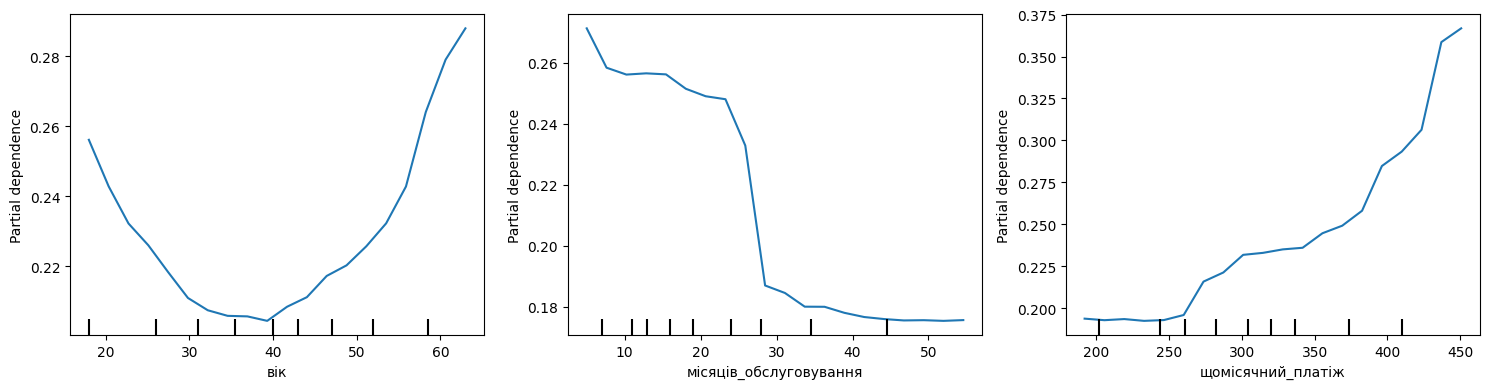

топ числових: ['вік', 'місяців_обслуговування', 'щомісячний_платіж']


In [81]:
from sklearn.inspection import PartialDependenceDisplay
NUM_TOP = [
    c for c in perm_imp.index
    if c in FINAL_X.select_dtypes(include='number').columns][:3]
fig,axs=plt.subplots(1,3,figsize=(15,4))
for ax,c in zip(axs,NUM_TOP):
 valid=Xte[Xte[c].notna()];PartialDependenceDisplay.from_estimator(model,valid,[c],ax=ax,grid_resolution=20)
plt.tight_layout();plt.show();print('топ числових:',NUM_TOP)

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

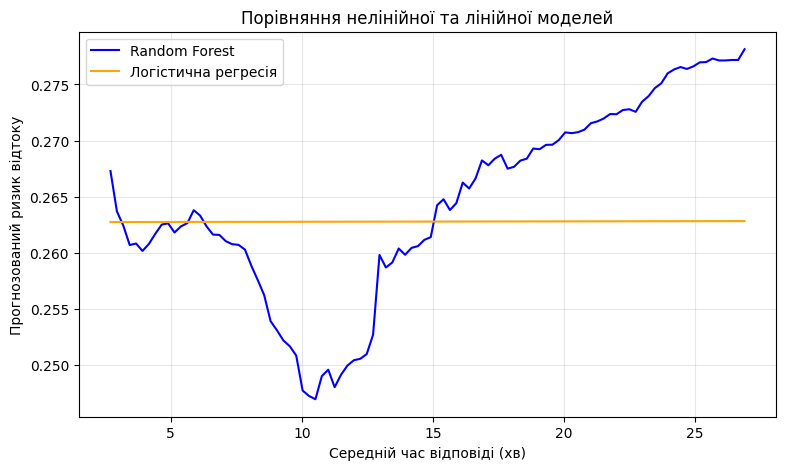

In [82]:

from sklearn.inspection import partial_dependence

NONLINEAR_FEATURE = 'середній_час_відповіді_хв'

valid = Xte[Xte[NONLINEAR_FEATURE].notna()].copy()

linear_model = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)

pd_forest = partial_dependence(
    model, valid, [NONLINEAR_FEATURE],
    method='brute',
    response_method='predict_proba'
)

pd_linear = partial_dependence(
    linear_model, valid, [NONLINEAR_FEATURE],
    method='brute',
    response_method='predict_proba'
)

plt.figure(figsize=(9, 5))

plt.plot(
    pd_forest['grid_values'][0],
    pd_forest['average'][0],
    label='Random Forest',
    color='blue'
)

plt.plot(
    pd_linear['grid_values'][0],
    pd_linear['average'][0],
    label='Логістична регресія',
    color='orange'
)

plt.xlabel('Середній час відповіді (хв)')
plt.ylabel('Прогнозований ризик відтоку')
plt.title('Порівняння нелінійної та лінійної моделей')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [44]:
NONLINEAR_MEANING='Ризик може бути мінімальним при помірному часі відповіді, а за надто малих або великих значень зростати; форму потрібно перевіряти на фактичній PDP.'
NONLINEAR_FIX='Додати квадрат відхилення часу відповіді від мінімуму ризику, оціненого на навчальній частині.'
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

Ризик може бути мінімальним при помірному часі відповіді, а за надто малих або великих значень зростати; форму потрібно перевіряти на фактичній PDP.
Додати квадрат відхилення часу відповіді від мінімуму ризику, оціненого на навчальній частині.


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [45]:
pd_result=partial_dependence(model,valid,[NONLINEAR_FEATURE],grid_resolution=25)
center=float(pd_result['grid_values'][0][np.argmin(pd_result['average'][0])])
Xquad=FINAL_X.copy();Xquad['квадрат_відхилення_часу']=(Xquad[NONLINEAR_FEATURE]-center)**2
quad_scores=cross_val_score(make_pipe(Xquad,logreg()),Xquad,y,cv=cv,scoring='roc_auc')
original_scores=cross_val_score(make_pipe(FINAL_X,logreg()),FINAL_X,y,cv=cv,scoring='roc_auc')
print('мінімум PDP:',center,'AUC до/після:',original_scores.mean(),quad_scores.mean())

мінімум PDP: 10.764666666666667 AUC до/після: 0.8107975188410623 0.8103217295626932


In [46]:
QUAD_GAIN=float(quad_scores.mean()-original_scores.mean())     # приріст AUC лінійної моделі від нової ознаки
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: -0.0005


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

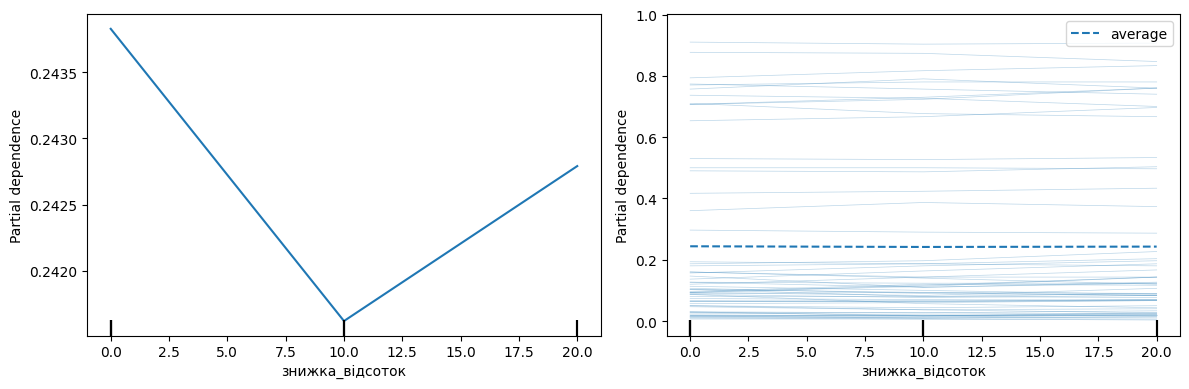

In [51]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
PartialDependenceDisplay.from_estimator(model,FINAL_X,['знижка_відсоток'],ax=axs[0],kind='average')
PartialDependenceDisplay.from_estimator(model,FINAL_X,['знижка_відсоток'],ax=axs[1],kind='both',subsample=60,random_state=SEED)
plt.tight_layout();plt.show()

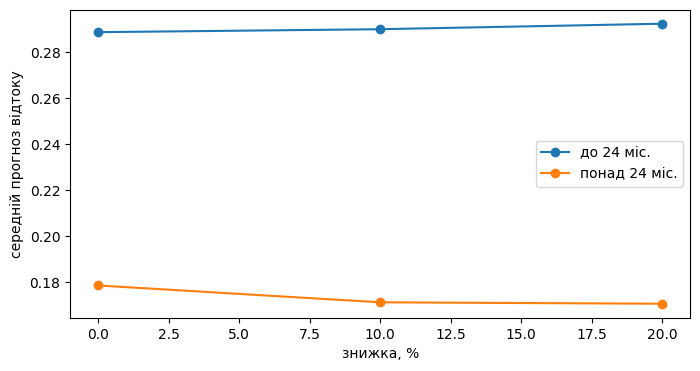

In [52]:
fig,ax=plt.subplots(figsize=(8,4))
for mask,label in [(FINAL_X['місяців_обслуговування']<=24,'до 24 міс.'),(FINAL_X['місяців_обслуговування']>24,'понад 24 міс.')]:
 subset=FINAL_X[mask]; pdp=partial_dependence(model,subset,['знижка_відсоток'],grid_resolution=3)
 ax.plot(pdp['grid_values'][0],pdp['average'][0],marker='o',label=label)
ax.set(xlabel='знижка, %',ylabel='середній прогноз відтоку');ax.legend();plt.show()

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [53]:
import shap
prep=model.named_steps['prep'];clf=model.named_steps['clf']
Xte_t=prep.transform(Xte);feat_names=prep.get_feature_names_out()
SAMPLE=min(60,Xte_t.shape[0]);expl=shap.TreeExplainer(clf);sv=expl.shap_values(Xte_t[:SAMPLE]);sv1=sv[...,1] if np.ndim(sv)==3 else sv
print('SHAP:',np.shape(sv1))

SHAP: (60, 48)


In [54]:
INTERACTION_FOUND='Зв’язок знижки з відтоком різний для клієнтів зі стажем до 24 місяців і понад 24; загальна PDP приховує цю взаємодію.'
BUSINESS_ACTION='Розглядати знижки окремо за стажем; спостережуваний зв’язок не доводить причинного ефекту, потрібен контрольований експеримент.'
print(INTERACTION_FOUND,BUSINESS_ACTION)

Зв’язок знижки з відтоком різний для клієнтів зі стажем до 24 місяців і понад 24; загальна PDP приховує цю взаємодію. Розглядати знижки окремо за стажем; спостережуваний зв’язок не доводить причинного ефекту, потрібен контрольований експеримент.


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [55]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 48)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

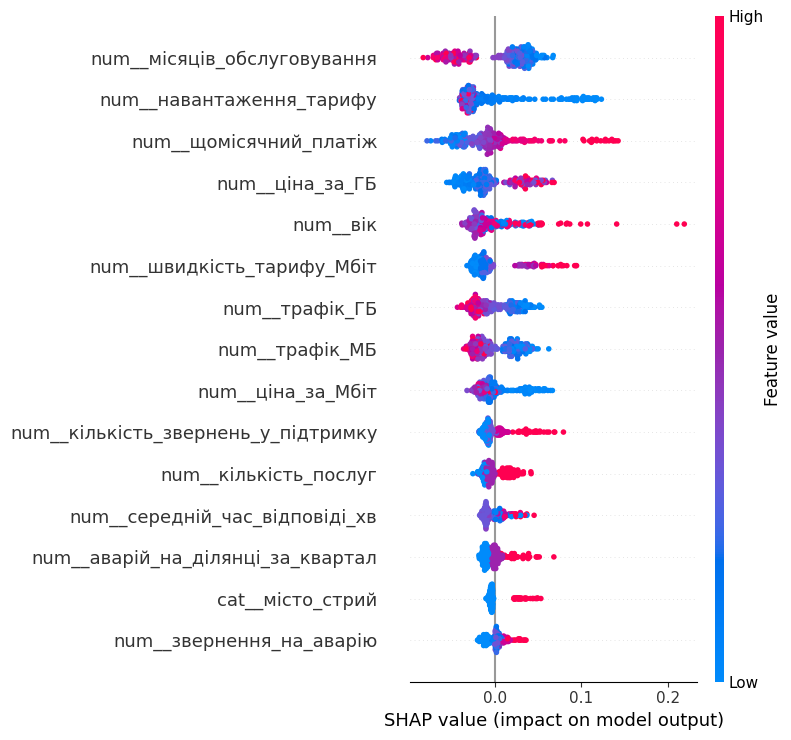

In [56]:
shap.summary_plot(sv1,Xte_t[:SAMPLE],feature_names=feat_names,show=False,max_display=15);plt.tight_layout();plt.show()

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [60]:
from IPython.display import display

idx = int(np.argmax(model.predict_proba(Xte.iloc[:SAMPLE])[:, 1]))

risk = float(model.predict_proba(Xte.iloc[[idx]])[0, 1])

contrib = pd.Series(
    sv1[idx],
    index=feat_names
).sort_values(key=abs, ascending=False)

print('ризик:', round(risk, 3))
display(contrib.head(10).to_frame('внесок SHAP'))


ризик: 0.803


,внесок SHAP
num__щомісячний_платіж,0.139849
num__навантаження_тарифу,0.117839
num__швидкість_тарифу_Мбіт,0.094461
num__ціна_за_Мбіт,0.057396
num__ціна_за_ГБ,0.054305
num__трафік_ГБ,0.040607
num__місяців_обслуговування,0.029222
num__трафік_МБ,0.025157
num__вік,-0.016165
num__кількість_послуг,-0.014892


In [58]:
EXPLANATION_FOR_MANAGER='Цього клієнта варто перевірити в першу чергу: розрахунковий ризик розірвання договору становить %.1f%%. Найбільші внески в оцінку наведено вище; перед пропозицією знижки перевірте історію звернень і якість обслуговування.'%(risk*100)
print(EXPLANATION_FOR_MANAGER)

Цього клієнта варто перевірити в першу чергу: розрахунковий ризик розірвання договору становить 80.3%. Найбільші внески в оцінку наведено вище; перед пропозицією знижки перевірте історію звернень і якість обслуговування.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [59]:
SHAP_NOT_CAUSAL_FEATURE='місяців_обслуговування'
SHAP_NOT_CAUSAL_WHY='Стаж клієнта може допомагати прогнозу, але його не можна змінити адміністративною дією; SHAP показує внесок у прогноз, а не причинний ефект.'
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

місяців_обслуговування — Стаж клієнта може допомагати прогнозу, але його не можна змінити адміністративною дією; SHAP показує внесок у прогноз, а не причинний ефект.


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [61]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",індекс_лояльності_CRM,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",трафік_ГБ + трафік_МБ,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",місяців_обслуговування,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [62]:
FIFTH_MISTAKE='Висока AUC на випадкових згортках не гарантує такої самої якості в іншій філії або в майбутньому. Через груповий артефакт збору потрібно окремо перевірити перенесення на нові філії та часовий тест, а не робити висновок тільки зі стратифікованої крос-валідації.'
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

Висока AUC на випадкових згортках не гарантує такої самої якості в іншій філії або в майбутньому. Через груповий артефакт збору потрібно окремо перевірити перенесення на нові філії та часовий тест, а не робити висновок тільки зі стратифікованої крос-валідації.


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [63]:
TOP_N=100
prob=model.predict_proba(Xte)[:,1];top_idx=np.argsort(-prob)[:TOP_N]
rate_top=float(yte.iloc[top_idx].mean());rate_all=float(yte.mean());lift=rate_top/rate_all
print('топ-100:',rate_top,'база:',rate_all,'lift:',lift)

топ-100: 0.54 база: 0.24722222222222223 lift: 2.1842696629213485


In [64]:
LIFT_MEANING='У перших 100 клієнтів рейтингу частка відтоку у %.2f раза більша за середню у відкладеній вибірці; це не доказ ефективності дзвінків.'%lift    # що число lift означає для бізнесу, одним реченням
assert LIFT_MEANING
print(LIFT_MEANING)

У перших 100 клієнтів рейтингу частка відтоку у 2.18 раза більша за середню у відкладеній вибірці; це не доказ ефективності дзвінків.


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [65]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_11.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [83]:
REPORT=f'''1. Метрика ROC AUC: класи незбалансовані; базова accuracy «ніхто не піде» = {1-y.mean():.3f}.
2. Вилучено id_клієнта (ідентифікатор), {', '.join(TARGET_LEAK)} (після розірвання), {', '.join(HUMAN_LEAK)} (після початку роботи з утриманням), {SUSPECT} (артефакт збору). Детектор пропусків не виявляє повністю заповнені поля з витоком.
3. Чесний AUC = {auc4.mean():.3f} ± {auc4.std():.3f}; різниця 0.004 за такого розкиду сама по собі не переконлива.
4. Артефакт філій: AUC джерела = {auc_src.mean():.3f}; на інші філії результат без додаткової перевірки не переноситься.
5. Нові ознаки ΔAUC = {paired(base,auc5)[0]:+.4f} ± {paired(base,auc5)[1]:.4f}; випадковий ліс ΔAUC = {MODEL_GAINS['випадковий ліс'][0]:+.4f} ± {MODEL_GAINS['випадковий ліс'][1]:.4f}; часи в таблиці розділу 7.
6. {FAKE_IMPORTANT}: багато можливих порогів розбиття завищують вбудовану важливість.
7. {DUP_PAIR}: одна ознака компенсує перестановку іншої; після видалення дубліката важливість залишеної зростає.
8. {NONLINEAR_FEATURE}: нелінійна форма; лінійній моделі потрібен квадрат відхилення, ΔAUC = {QUAD_GAIN:+.4f}.
9. Загальна PDP знижки усереднює різні залежності для клієнтів до 24 місяців і понад 24; ICE показує неоднорідність.
10. {SHAP_NOT_CAUSAL_FEATURE}: внесок у прогноз не є причинністю; стаж не можна змінити рішенням менеджера.
11. Lift для топ-100 = {lift:.3f}; варто перевіряти ці 100 заявок, але знижки та дзвінки треба тестувати експериментально.
Декларація про використання ШІ: ШІ допоміг доповнити код, зрозуміти ціль метрик та розʼяснити нові терміни.'''
print(REPORT)

1. Метрика ROC AUC: класи незбалансовані; базова accuracy «ніхто не піде» = 0.753.
2. Вилучено id_клієнта (ідентифікатор), код_причини_закриття, дата_розірвання (після розірвання), кількість_дзвінків_утримання (після початку роботи з утриманням), філія (артефакт збору). Детектор пропусків не виявляє повністю заповнені поля з витоком.
3. Чесний AUC = 0.815 ± 0.027; різниця 0.004 за такого розкиду сама по собі не переконлива.
4. Артефакт філій: AUC джерела = 0.700; на інші філії результат без додаткової перевірки не переноситься.
5. Нові ознаки ΔAUC = -0.0037 ± 0.0012; випадковий ліс ΔAUC = +0.0092 ± 0.0089; часи в таблиці розділу 7.
6. індекс_лояльності_CRM: багато можливих порогів розбиття завищують вбудовану важливість.
7. ['трафік_ГБ', 'трафік_МБ']: одна ознака компенсує перестановку іншої; після видалення дубліката важливість залишеної зростає.
8. середній_час_відповіді_хв: нелінійна форма; лінійній моделі потрібен квадрат відхилення, ΔAUC = -0.0005.
9. Загальна PDP знижки усереднює

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.